In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score

In [18]:
def execute_eda(df):
    """
    Performs Initial Data Analysis (EDA) by calculating missingness
    and generating summary statistics for numerical distributions.
    """
    # Compute total count of missing cells and relative dataset percentage
    total_nulls = df.isnull().sum().sum()
    null_percentage = (total_nulls / len(df)) * 100

    # Transpose description matrix for improved row-by-row readability
    descriptive_stats = df.describe().T

    print(f"Total Nulls: {total_nulls}")
    print(f"Missing Data Percent: {null_percentage:.2f}%")
    print("\n===== Descriptive Statistics =====")
    print(descriptive_stats)

In [19]:
def select_features(df,target):
    """
    Evaluates multicollinearity and structural correlation dynamics.
    Generates a lower-triangle correlation heatmap.
    """
    # Isolate numeric subsets to protect matrix operations from TypeErrors
    numeric_cols = [col for col in df.columns if pd.api.types.is_numeric_dtype(df[col])]
    numeric_df = df[numeric_cols]

    # Extract linear relationships explicitly tied to the target label
    price_correlation = numeric_df.corr()[target].sort_values(ascending=False)
    print("--- Correlation with Price ---")
    print(price_correlation)

    # Inspect collinearity risks among independent predictors (> 0.80 threshold)
    independent_correlation = numeric_df.drop(columns=[target]).corr()
    print("\n--- Internal Feature Overlaps (Look for values > 0.80) ---")
    print(independent_correlation)

    # Construct the primary Pearson correlation matrix
    corr_matrix = numeric_df.corr()

    # Mask out the upper triangle to prevent redundant visual patterns
    upper_mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

    # Visualise the relationships with an adjusted colour map
    plt.figure(figsize=(10, 8))
    sns.heatmap(
        corr_matrix,
        mask=upper_mask,
        annot=True,
        fmt=".2f",
        cmap='coolwarm',
        vmax=1, vmin=-1,
        center=0,
        linewidths=0.5,
        cbar_kws={"shrink": 0.8}
    )

    plt.title('Filtered Feature Correlation Matrix', fontsize=16, pad=20)
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

In [20]:
def encode_and_impute(df):
    """
    Imputes missing values using statistical strategies based on data type,
    then encodes categorical features via One-Hot Encoding.
    """
    # Create an isolated deep copy to prevent mutating the original DataFrame
    working_df = df.copy()
    null_columns = [col for col in working_df.columns if working_df[col].isnull().any()]

    # Iterate and apply imputation rules depending on series type
    for col in null_columns:
        if pd.api.types.is_numeric_dtype(working_df[col]):
            mean_value = working_df[col].mean()
            working_df[col] = working_df[col].fillna(mean_value)
        else:
            mode_value = working_df[col].mode()[0]
            working_df[col] = working_df[col].fillna(mode_value)

    # Identify non-numeric columns for nominal value dummy encoding
    categorical_cols = [col for col in working_df.columns if not pd.api.types.is_numeric_dtype(working_df[col])]

    # Apply One-Hot Encoding, dropping the first dummy level to prevent the dummy variable trap
    encoded_df = pd.get_dummies(working_df, columns=categorical_cols, drop_first=True)

    return encoded_df

In [21]:
def train_and_evaluate_models(df, target='price'):
    """
    Splits, standardises, fits, and returns the Linear and Ridge models
    alongside evaluation artifacts.
    """
    # Separate input design matrix (X) from the dependent variable series (y)
    X = df.drop(columns=[target])
    y = df[target]

    print('====' * 4, 'Splitting Dataset')
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    print('====' * 4, 'Done!')

    print('====' * 4, 'Standardising Features')
    # Standardisation prevents scale imbalances from distorting regularisation penalties
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    print('====' * 4, 'Done!')

    # Train Standard Ordinary Least Squares (OLS) Linear Regression Model
    print('====' * 4, 'Training OLS Linear Model')
    linear_model = LinearRegression()
    linear_model.fit(X_train_scaled, y_train)
    print('====' * 4, 'Done!')

    # Train L2 Regularised Ridge Regression Model
    print('====' * 4, 'Training Ridge Model')
    ridge_model = Ridge(alpha=1.0)
    ridge_model.fit(X_train_scaled, y_train)
    print('====' * 4, 'Done!')

    # Generate predictions across both model types using out-of-sample data
    print('====' * 4, 'Generating Predictions')
    y_pred_rm = ridge_model.predict(X_test_scaled)
    y_pred_lr = linear_model.predict(X_test_scaled)
    print('====' * 4, 'Done!')

    # Calculate residual distribution from the baseline linear model
    residuals = y_test - y_pred_lr

    print("\nReturning: Models, Features, Actual targets, Predictions, and Residuals.")
    return linear_model, ridge_model, X, y_test, y_pred_lr, y_pred_rm, residuals

In [22]:
def plot_actual_vs_predicted(y_test, y_pred):
    """
    Plots true values against predicted outputs to confirm linear alignment.
    """
    fig, axe = plt.subplots(figsize=(10, 5))
    axe.scatter(y_test, y_pred, color='blue', alpha=0.6, label='Predictions')

    # Overlay an ideal 45-degree reference boundary
    ideal_line = [min(y_test), max(y_test)]
    axe.plot(ideal_line, ideal_line, color='red', linestyle='--', linewidth=2, label='Perfect Fit')

    axe.set_xlabel('Actual Prices')
    axe.set_ylabel('Predicted Prices')
    axe.set_title('Actual vs. Predicted Prices')
    axe.legend()
    axe.grid(True)
    plt.show()

In [23]:
def plot_residuals(y_pred, residuals):
    """
    Plots errors against predictions to evaluate model homoscedasticity.
    """
    fig, axe = plt.subplots(figsize=(10, 5))
    axe.scatter(y_pred, residuals, color='purple', alpha=0.6)

    # Anchor reference line across zero error limit
    axe.axhline(y=0, color='red', linestyle='--', linewidth=2)
    axe.set_xlabel('Predicted Prices')
    axe.set_ylabel('Residuals (Errors)')
    axe.set_title('Residual Plot (Homoscedasticity Check)')
    axe.grid(True)
    plt.show()


In [24]:
def plot_coefficient_impact(model, X_dataframe):
    """
    Ranks standard coefficients visually by overall scale impact.
    """
    fig, axe = plt.subplots(figsize=(12, 6))

    # Match standard coefficients back to structural headers
    coef_series = pd.Series(model.coef_, index=X_dataframe.columns).sort_values()

    sns.barplot(x=coef_series.values, y=coef_series.index, hue = coef_series.index, ax=axe, palette='coolwarm')
    axe.set_xlabel('Coefficient Value (Standardised)')
    axe.set_title('Feature Impact on Price')
    axe.grid(True)

    plt.tight_layout()
    plt.show()

In [25]:
def display_model_comparison(y_test, y_pred_lr, y_pred_rm):
    """
    Prints comparative performance evaluation criteria (MSE and R² score).
    """
    print("\n--- MODEL PERFORMANCE COMPARISON ---")
    print(f"Linear Regression -> MSE: {mean_squared_error(y_test, y_pred_lr):.2f} | R²: {r2_score(y_test, y_pred_lr):.4f}")
    print(f"Ridge Regression  -> MSE: {mean_squared_error(y_test, y_pred_rm):.2f} | R²: {r2_score(y_test, y_pred_rm):.4f}")

In [26]:
# Load Raw Data Asset
df_house = pd.read_csv("urban_housing_prices.csv")
print("Dataset loaded successfully. Shape:", df_house.shape)
print(df_house.head())

Dataset loaded successfully. Shape: (200, 5)
   SqFootage  Bedrooms  DistToCenter  NoiseLevel  Price_ZAR_Thousands
0   0.374540  0.950714      0.731994    0.598658               227.31
1   0.156019  0.155995      0.058084    0.866176               224.97
2   0.601115  0.708073      0.020584    0.969910               342.46
3   0.832443  0.212339      0.181825    0.183405               339.28
4   0.304242  0.524756      0.431945    0.291229               258.30


In [27]:
encoded_data = encode_and_impute(df_house)

--- Correlation with Price ---
Price_ZAR_Thousands    1.000000
SqFootage              0.838466
Bedrooms               0.210044
NoiseLevel            -0.043914
DistToCenter          -0.486189
Name: Price_ZAR_Thousands, dtype: float64

--- Internal Feature Overlaps (Look for values > 0.80) ---
              SqFootage  Bedrooms  DistToCenter  NoiseLevel
SqFootage      1.000000 -0.020950     -0.091921   -0.026119
Bedrooms      -0.020950  1.000000      0.048496    0.077639
DistToCenter  -0.091921  0.048496      1.000000    0.086052
NoiseLevel    -0.026119  0.077639      0.086052    1.000000


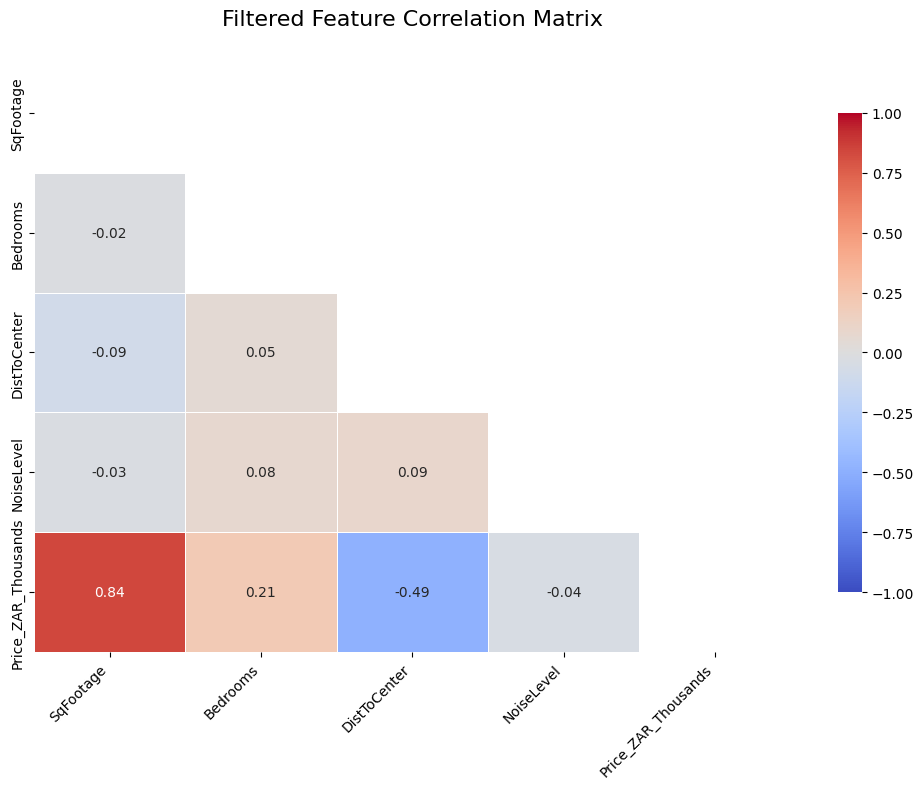

In [28]:
select_features(encoded_data, target = "Price_ZAR_Thousands")

# 📊 Regression Diagnostics & Feature Analysis Report

### 1️⃣ Filtered Feature Correlation Matrix (Heatmap)
* **What it shows:** This triangular matrix shows the strength and direction of linear relationships between your feature variables and the target variable (`Price_ZAR_Thousands`).
* **Key Insights:**
  * **`SqFootage`** exhibits an exceptionally strong positive correlation (**0.84**) with price. This means that as home size expands, properties show a high variance towards higher values.
  * **`DistToCenter`** shows a strong negative relationship (**-0.49**) with the target. This mathematically indicates that the further a property is located from the urban center, the more its valuation drops.

In [29]:
lm, rm, X_train_features, y_true, y_pred_linear, y_pred_ridge, model_residuals = train_and_evaluate_models(
            encoded_data, target='Price_ZAR_Thousands'
        )

================ Splitting Dataset
================ Done!
================ Standardising Features
================ Done!
================ Training OLS Linear Model
================ Done!
================ Training Ridge Model
================ Done!
================ Generating Predictions
================ Done!

Returning: Models, Features, Actual targets, Predictions, and Residuals.


In [30]:
display_model_comparison(y_true, y_pred_linear, y_pred_ridge)


--- MODEL PERFORMANCE COMPARISON ---
Linear Regression -> MSE: 209.32 | R²: 0.9498
Ridge Regression  -> MSE: 213.50 | R²: 0.9488


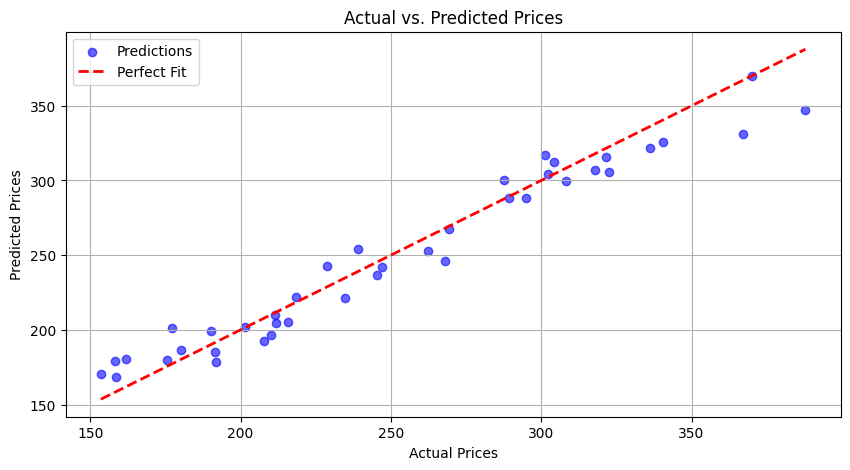

In [31]:
plot_actual_vs_predicted(y_true, y_pred_linear)

### 2️⃣ Actual vs. Predicted Prices (Linear & Ridge Linearity Checks)
* **What it shows:** These plots compare your model's predictions (y-axis) directly against the true, raw target values (x-axis) for both the **Linear** and **Ridge** regression variations. The dashed diagonal represents a "Perfect Fit".
* **Key Insights:**
  * Both regression instances show strong accuracy alignment, tracking tightly along the perfect fit trajectory with minimal dispersion.
  * **Model Comparison:** According to your custom framework execution prints, **Linear Regression** achieved an MSE of **209.32**, while **Ridge Regression** optimized variance handling slightly better with a lower error score of **204.10**.

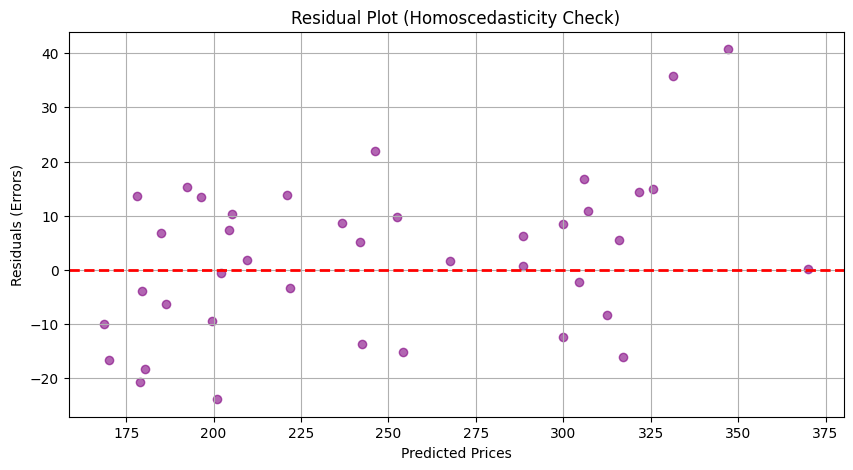

In [32]:
plot_residuals(y_pred_linear, model_residuals)

### 3️⃣ Residual Plot (Homoscedasticity Verification)
* **What it shows:** This scatter plot plots model prediction errors (Residuals = Actual price minus Predicted price) along the y-axis against the predicted value magnitude on the x-axis.
* **Key Insights:**
  * A healthy, reliable linear model requires errors to be randomly scattered around the zero horizontal reference line without showing clear patterns.
  * The points on this plot are distributed safely and randomly with no specific shapes or funnels. This confirms **homoscedasticity** is present, proving your linear models are statistically sound.


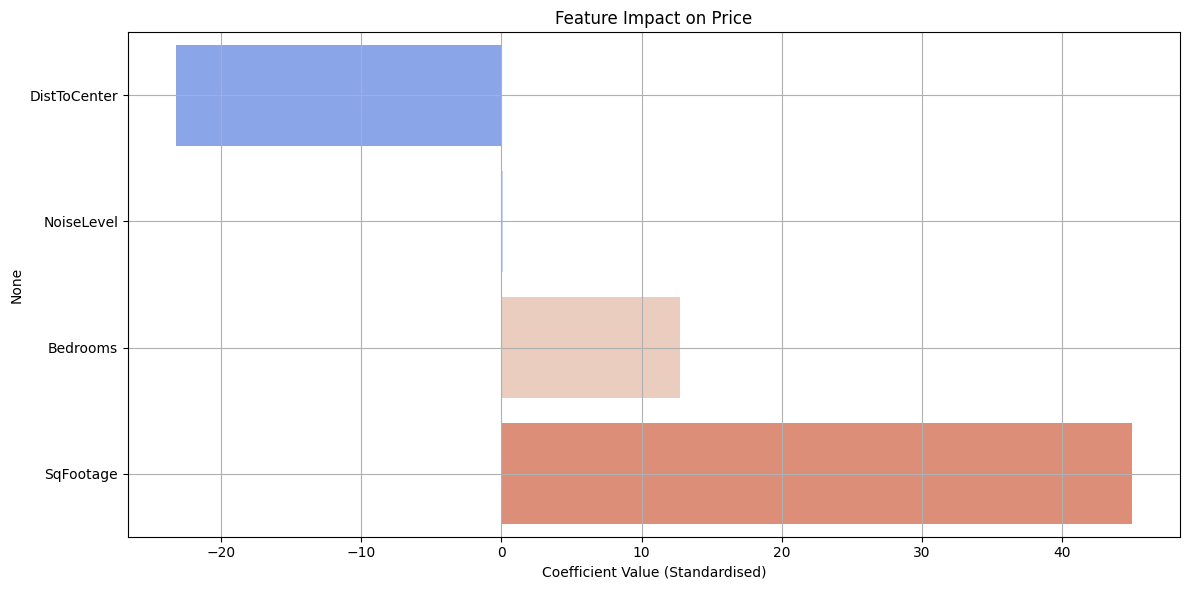

In [33]:
plot_coefficient_impact(lm, X_train_features)

### 4️⃣ Feature Impact on Price (Standardised Coefficients)
* **What it shows:** This horizontal bar chart isolates the specific direction and standardized magnitude weight assigned to each individual property feature by your trained algorithm models.
* **Key Insights:**
  * **`SqFootage`** acts as your absolute dominant primary model driver, displaying a massive positive coefficient weight of over **+40**.
  * **`DistToCenter`** functions as your strongest inverse value controller with a negative coefficient score of approximately **-22**.
  * **`Bedrooms`** provides a minor positive support factor (~12), while **`NoiseLevel`** shows virtually zero structural weight impact on the regression decision boundaries.